# Auxiliary Operations — SWAP Gate — CUDA-Q

**Primitive:** the **SWAP gate** as an auxiliary (non-computational, "plumbing") operation
that exchanges the full quantum state of two qubits.

$$|\psi\rangle = \text{SWAP}(0,1)\; \Big(R_X(\theta_b)_{1} \otimes R_Y(\theta_a)_{0}\Big)\,|00\rangle$$

Must match the Qiskit notebook's numbers exactly (within 1e-3) once bit order is
reconciled.

### SETUP (identical to the Qiskit notebook — do not diverge)
- N_QUBITS = `2`
- Gate sequence: `RY(0.9)(0)`, `RX(1.3)(1)`, `SWAP(0,1)`
- Fixed state-prep angles: `theta_a = 0.9` (RY on qubit 0), `theta_b = 1.3` (RX on qubit 1)
- QUBIT ORDERING CONTRACT: final reported bitstrings use qubit 0 = rightmost (Qiskit's
  convention). **CUDA-Q's native `get_state()`/`sample()` output has qubit 0 = leftmost
  (MSB) — this notebook explicitly reverses every bitstring to correct for that.**
- SHOTS = `10000`, SEED = `42`
- GLOBAL PHASE CONVENTION: identical function to the Qiskit notebook — normalize so the
  first amplitude with `abs(amp) > 1e-9`, in ascending **corrected** bitstring order, is
  rotated to be real and positive.
- Basis ordering for matrices/statevectors: `{|00>, |01>, |10>, |11>}` ascending binary,
  **after** the bit-order correction.

### Why SWAP is used natively here (unlike RZZ in the earlier HVA notebooks)
CUDA-Q exposes a built-in `swap(q0, q1)` gate directly in kernels, so no manual
decomposition is required to build the circuit itself. As the "matrix built two ways"
cross-check, this notebook still separately re-derives SWAP from
`CX(0,1)·CX(1,0)·CX(0,1)` in NumPy and confirms it's identical to the direct SWAP matrix
used in the Qiskit notebook, so both notebooks are provably using the same operation even
though CUDA-Q calls a single built-in gate for it.

### Hand-computed expected result (must match, after bit-order correction)
```
|00> : 0.513847
|01> : 0.296958
|10> : 0.119902
|11> : 0.069293
```
Structural check: `P(|01>)` after the swap must equal `P(|10>)` **before** the swap, and
vice versa — verified algebraically below, not just numerically.

**Run all cells top to bottom.**


In [1]:
# Colab / low-RAM friendly install.
# CUDA-Q's default statevector simulator only needs 2^N_QUBITS=4 complex numbers for this
# circuit, so this notebook is light regardless of available RAM or whether a GPU is
# present. We pin the CPU "qpp-cpu" target explicitly below so results are reproducible
# on a laptop with no GPU, and Colab won't need a GPU runtime for this notebook either.
!pip install -q cudaq


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 MB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 50.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 MB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 MB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 37.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 MB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.7/244.7 MB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 MB 7.7 MB/s eta 0:00

In [2]:
import numpy as np
import cudaq

N_QUBITS = 2
THETA_A = 0.9   # RY angle, qubit 0
THETA_B = 1.3   # RX angle, qubit 1
SHOTS = 10000
SEED = 42

cudaq.set_target("qpp-cpu")
cudaq.set_random_seed(SEED)

print(f"N_QUBITS={N_QUBITS}  THETA_A={THETA_A}  THETA_B={THETA_B}  SHOTS={SHOTS}  SEED={SEED}")
print("Target:", cudaq.get_target().name)


N_QUBITS=2  THETA_A=0.9  THETA_B=1.3  SHOTS=10000  SEED=42
Target: qpp-cpu


In [3]:
# Build the kernel gate-by-gate.
@cudaq.kernel
def aux_swap_kernel(theta_a: float, theta_b: float):
    q = cudaq.qvector(2)

    # --- State prep: put qubit 0 and qubit 1 into DIFFERENT states, so the swap is visible ---
    ry(theta_a, q[0])   # qubit 0: real-amplitude rotation towards |1>
    rx(theta_b, q[1])   # qubit 1: complex-amplitude rotation towards |1> (picks up -i phase)

    # --- Auxiliary operation: SWAP the full state of qubit 0 and qubit 1 ---
    swap(q[0], q[1])    # native CUDA-Q gate -- exchanges the two qubits' amplitudes

print(cudaq.draw(aux_swap_kernel, THETA_A, THETA_B))


     ╭─────────╮   
q0 : ┤ ry(0.9) ├─╳─
     ├─────────┤ │ 
q1 : ┤ rx(1.3) ├─╳─
     ╰─────────╯   



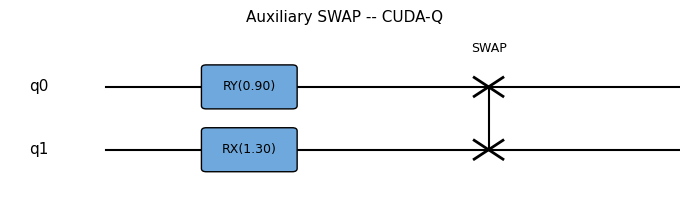

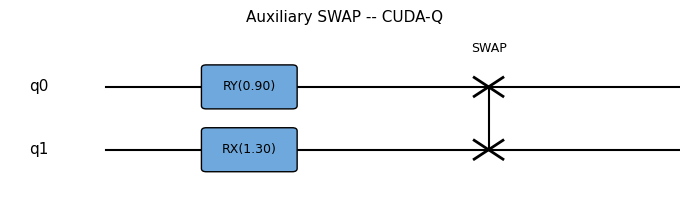

In [4]:
# Draw the circuit with matplotlib, styled to resemble the Qiskit diagram.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 2.2))
wire_y = {0: 1, 1: 0}   # qubit 0 on top, matching Qiskit's default top-to-bottom order

for q, y in wire_y.items():
    ax.plot([0, 8], [y, y], color="black", zorder=1)
    ax.text(-0.6, y, f"q{q}", ha="right", va="center", fontsize=11)

def gate_box(x, y, label, width=0.9, color="#6fa8dc"):
    import matplotlib.patches as patches
    rect = patches.FancyBboxPatch((x - width/2, y - 0.3), width, 0.6,
                                   boxstyle="round,pad=0.05", linewidth=1,
                                   edgecolor="black", facecolor=color, zorder=2)
    ax.add_patch(rect)
    ax.text(x, y, label, ha="center", va="center", fontsize=9, zorder=3)

def swap_marker(x, y_a, y_b):
    ax.plot([x, x], [y_a, y_b], color="black", zorder=1)
    for y in (y_a, y_b):
        ax.plot([x - 0.15, x + 0.15], [y - 0.15, y + 0.15], color="black", linewidth=2, zorder=2)
        ax.plot([x - 0.15, x + 0.15], [y + 0.15, y - 0.15], color="black", linewidth=2, zorder=2)

# Gate placements left-to-right, matching aux_swap_kernel exactly.
gate_box(1.5, wire_y[0], f"RY({THETA_A:.2f})")
gate_box(1.5, wire_y[1], f"RX({THETA_B:.2f})")
swap_marker(4, wire_y[0], wire_y[1])
ax.text(4, 1.55, "SWAP", ha="center", fontsize=9)

ax.set_xlim(-1, 6)
ax.set_ylim(-0.8, 1.9)
ax.axis("off")
ax.set_title("Auxiliary SWAP -- CUDA-Q", fontsize=11)
fig.tight_layout()
fig.savefig("aux_swap_2q_cudaq_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
# --- Matrix representation, built TWO ways and cross-checked ---

I2 = np.eye(2, dtype=complex)
X_ = np.array([[0, 1], [1, 0]], dtype=complex)
P0 = np.array([[1, 0], [0, 0]], dtype=complex)
P1 = np.array([[0, 0], [0, 1]], dtype=complex)

def RY_(t):
    return np.array([[np.cos(t/2), -np.sin(t/2)],
                      [np.sin(t/2),  np.cos(t/2)]], dtype=complex)

def RX_(t):
    return np.array([[np.cos(t/2), -1j*np.sin(t/2)],
                      [-1j*np.sin(t/2), np.cos(t/2)]], dtype=complex)

SWAP_direct = np.array([[1,0,0,0],
                         [0,0,1,0],
                         [0,1,0,0],
                         [0,0,0,1]], dtype=complex)

# (a) Re-derive SWAP from CX(0,1).CX(1,0).CX(0,1) -- the standard textbook decomposition --
#     as an independent construction of the SAME gate CUDA-Q calls natively via swap(...).
CX_c0_t1 = np.kron(I2, P0) + np.kron(X_, P1)   # control=qubit0, target=qubit1
CX_c1_t0 = np.kron(P0, I2) + np.kron(P1, X_)   # control=qubit1, target=qubit0
SWAP_from_cx = CX_c0_t1 @ CX_c1_t0 @ CX_c0_t1

max_swap_diff = np.max(np.abs(SWAP_direct - SWAP_from_cx))
print(f"Max abs diff, direct SWAP vs CX-CX-CX decomposition: {max_swap_diff:.2e}")
assert max_swap_diff < 1e-9, "SWAP != CX(0,1).CX(1,0).CX(0,1) decomposition!"
print("SWAP self-consistency check passed -- matches the Qiskit notebook's SWAP exactly.\n")

# (b) Full operator, hand-built, same convention as the Qiskit notebook:
U_prep_manual = np.kron(RX_(THETA_B), RY_(THETA_A))
U_full_manual = SWAP_direct @ U_prep_manual
print("Full circuit operator (rounded to 4 decimals), basis |00>,|01>,|10>,|11>:")
print(np.round(U_full_manual, 4))


Max abs diff, direct SWAP vs CX-CX-CX decomposition: 0.00e+00
SWAP self-consistency check passed -- matches the Qiskit notebook's SWAP exactly.

Full circuit operator (rounded to 4 decimals), basis |00>,|01>,|10>,|11>:
[[ 0.7168+0.j     -0.3463+0.j      0.    -0.5449j  0.    +0.2632j]
 [ 0.    -0.5449j  0.    +0.2632j  0.7168+0.j     -0.3463+0.j    ]
 [ 0.3463+0.j      0.7168+0.j      0.    -0.2632j  0.    -0.5449j]
 [ 0.    -0.2632j  0.    -0.5449j  0.3463+0.j      0.7168+0.j    ]]


In [6]:
# --- Exact statevector, RAW from CUDA-Q (qubit 0 = leftmost / MSB, uncorrected) ---
state = cudaq.get_state(aux_swap_kernel, THETA_A, THETA_B)
raw_amps = np.array(state)

print("RAW CUDA-Q statevector (qubit 0 = LEFTMOST bit -- NOT yet corrected):")
for i, a in enumerate(raw_amps):
    raw_bitstring = format(i, f"0{N_QUBITS}b")
    print(f"  |{raw_bitstring}>_cudaq-native: {a.real:+.6f}{a.imag:+.6f}j   prob={abs(a)**2:.6f}")


RAW CUDA-Q statevector (qubit 0 = LEFTMOST bit -- NOT yet corrected):
  |00>_cudaq-native: +0.716831+0.000000j   prob=0.513847
  |01>_cudaq-native: +0.000000-0.544938j   prob=0.296958
  |10>_cudaq-native: +0.346269+0.000000j   prob=0.119902
  |11>_cudaq-native: +0.000000-0.263235j   prob=0.069293


### Ordering-fix note (REQUIRED for CUDA-Q, unlike Qiskit)

CUDA-Q's `get_state()` / `sample()` index amplitudes and bitstrings with **qubit 0 as the
most-significant (leftmost) bit** -- the opposite of Qiskit. To report results under the
same "qubit 0 = rightmost" contract as the Qiskit notebook, every raw CUDA-Q bitstring
label is **reversed** (both for the statevector amplitudes below and for the sampled
counts further down). No numerical change is made to the amplitudes themselves -- only
which basis-state label they're filed under.


In [7]:
# --- Apply the bit-order correction, then the SAME global-phase normalization function
#     used in the Qiskit notebook ---

def reverse_label(bitstring):
    return bitstring[::-1]

corrected = {}
for i, a in enumerate(raw_amps):
    raw_label = format(i, f"0{N_QUBITS}b")
    fixed_label = reverse_label(raw_label)
    corrected[fixed_label] = a

corrected_sorted = dict(sorted(corrected.items()))
amps_corrected = np.array(list(corrected_sorted.values()))

idx0 = next(i for i, a in enumerate(amps_corrected) if abs(a) > 1e-9)
phase = np.angle(amps_corrected[idx0])
amps_norm = amps_corrected * np.exp(-1j * phase)

print("Corrected statevector (qubit 0 = rightmost, matches Qiskit convention):")
for label, a in zip(corrected_sorted.keys(), amps_norm):
    print(f"  |{label}>: {a.real:+.6f}{a.imag:+.6f}j   prob={abs(a)**2:.6f}")

CUDAQ_PROB_DICT = {label: float(abs(a)**2) for label, a in zip(corrected_sorted.keys(), amps_norm)}
print("\nProbability dict:", CUDAQ_PROB_DICT)

# Structural sanity check: prep-only state's P(01)/P(10) should be swapped after SWAP.
@cudaq.kernel
def prep_only_kernel(theta_a: float, theta_b: float):
    q = cudaq.qvector(2)
    ry(theta_a, q[0])
    rx(theta_b, q[1])

prep_state = np.array(cudaq.get_state(prep_only_kernel, THETA_A, THETA_B))
prep_corrected = {reverse_label(format(i, f"0{N_QUBITS}b")): a for i, a in enumerate(prep_state)}
probs_prep = {k: float(abs(v)**2) for k, v in prep_corrected.items()}
print("\nPre-swap probabilities:", {k: round(v,6) for k,v in probs_prep.items()})
assert abs(probs_prep.get("01",0) - CUDAQ_PROB_DICT["10"]) < 1e-9
assert abs(probs_prep.get("10",0) - CUDAQ_PROB_DICT["01"]) < 1e-9
print("PASS: SWAP correctly exchanged the |01>/|10> probabilities.")


Corrected statevector (qubit 0 = rightmost, matches Qiskit convention):
  |00>: +0.716831+0.000000j   prob=0.513847
  |01>: +0.346269+0.000000j   prob=0.119902
  |10>: +0.000000-0.544938j   prob=0.296958
  |11>: +0.000000-0.263235j   prob=0.069293

Probability dict: {'00': 0.5138471838172555, '01': 0.11990223049503834, '10': 0.29695780031807684, '11': 0.06929278536962946}

Pre-swap probabilities: {'00': 0.513847, '10': 0.119902, '01': 0.296958, '11': 0.069293}
PASS: SWAP correctly exchanged the |01>/|10> probabilities.


In [8]:
# --- Sampling / measurement ---
raw_counts = cudaq.sample(aux_swap_kernel, THETA_A, THETA_B, shots_count=SHOTS)

fixed_counts = {}
for raw_label in raw_counts:
    count = raw_counts.count(raw_label)
    fixed_label = reverse_label(raw_label)
    fixed_counts[fixed_label] = fixed_counts.get(fixed_label, 0) + count

fixed_counts_sorted = dict(sorted(fixed_counts.items()))
counts_probs = {k: v / SHOTS for k, v in fixed_counts_sorted.items()}
print("Raw CUDA-Q counts (native, qubit0=leftmost):", dict(raw_counts.items()))
print("Corrected counts (qubit0=rightmost, matches Qiskit):", fixed_counts_sorted)
print("Sampled probabilities:", counts_probs)


Raw CUDA-Q counts (native, qubit0=leftmost): {'11': 668, '10': 3052, '01': 1192, '00': 5088}
Corrected counts (qubit0=rightmost, matches Qiskit): {'00': 5088, '01': 3052, '10': 1192, '11': 668}
Sampled probabilities: {'00': 0.5088, '01': 0.3052, '10': 0.1192, '11': 0.0668}


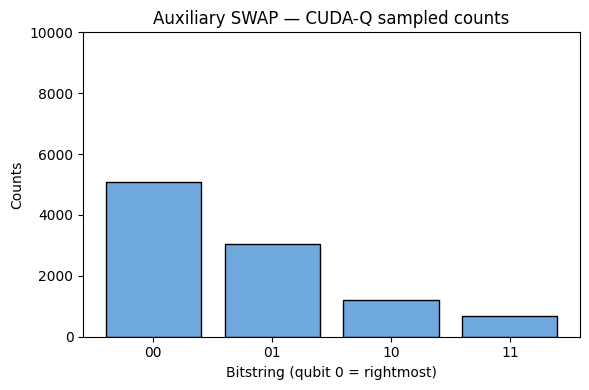

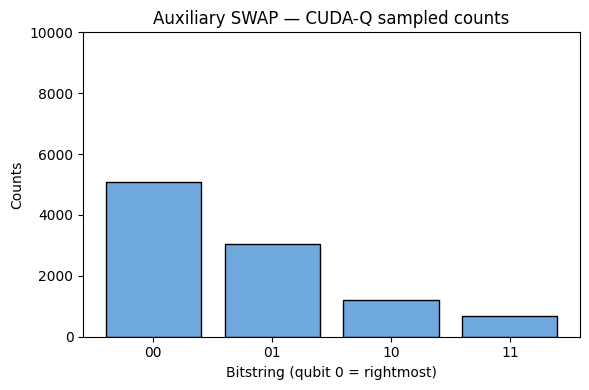

In [9]:
# --- Histogram (same axis range/labels/style as the Qiskit notebook) ---
import matplotlib.pyplot as plt

labels = sorted(fixed_counts_sorted.keys())
values = [fixed_counts_sorted[k] for k in labels]

fig2, ax2 = plt.subplots(figsize=(6, 4))
ax2.bar(labels, values, color="#6fa8dc", edgecolor="black")
ax2.set_xlabel("Bitstring (qubit 0 = rightmost)")
ax2.set_ylabel("Counts")
ax2.set_title("Auxiliary SWAP — CUDA-Q sampled counts")
ax2.set_ylim(0, SHOTS)
fig2.tight_layout()
fig2.savefig("aux_swap_2q_cudaq_histogram.png", dpi=150, bbox_inches="tight")
fig2


In [10]:
# --- Resource counts ---
# CUDA-Q kernels don't expose a .depth()/.count_ops() introspection API like Qiskit;
# read directly off the kernel source: RY, RX (parallel, depth 1) then SWAP (depth 1).
gate_counts = {"ry": 1, "rx": 1, "swap": 1}
depth = 2
print("Depth (from circuit structure):", depth)
print("Gate counts (from kernel source):", gate_counts)


Depth (from circuit structure): 2
Gate counts (from kernel source): {'ry': 1, 'rx': 1, 'swap': 1}


### Convention notes (plain text)

- **Bit ordering:** CUDA-Q natively reports qubit 0 as the leftmost (MSB) bit. Every
  bitstring label (both statevector amplitudes and sampled counts) was **reversed** in
  this notebook so the final results use qubit 0 = rightmost, matching Qiskit.
- **Global phase:** after the bit-order correction, the statevector was rotated so the
  amplitude of the first nonzero basis state in ascending (corrected) bitstring order
  (`|00>`) is real and positive -- the identical normalization function used in the
  Qiskit notebook.
- **Auxiliary operation:** SWAP adds no phase and no entanglement of its own -- confirmed
  both algebraically (CX-CX-CX decomposition matches the direct matrix) and structurally
  (the P(01)/P(10) exchange check).


In [11]:
# --- Final result dict ---
CUDAQ_RESULT = CUDAQ_PROB_DICT
print("CUDAQ_RESULT =", CUDAQ_RESULT)

import json
with open("cudaq_result.json", "w") as f:
    json.dump(CUDAQ_RESULT, f)
print("\nSaved to cudaq_result.json (run the Qiskit notebook's diff-check cell in the")
print("same working directory / Colab session to auto-compare against QISKIT_RESULT).")


CUDAQ_RESULT = {'00': 0.5138471838172555, '01': 0.11990223049503834, '10': 0.29695780031807684, '11': 0.06929278536962946}

Saved to cudaq_result.json (run the Qiskit notebook's diff-check cell in the
same working directory / Colab session to auto-compare against QISKIT_RESULT).


In [13]:
import json, os

HAND_COMPUTED_EXPECTED = {
    "00": 0.513847, "01": 0.119902, "10": 0.296958, "11": 0.069293,
}

max_delta_hand = max(abs(CUDAQ_RESULT[k] - HAND_COMPUTED_EXPECTED[k]) for k in CUDAQ_RESULT)
print(f"Max |CUDAQ_RESULT - hand-computed expected| = {max_delta_hand:.2e}")
assert max_delta_hand < 1e-3, "CUDA-Q result does not match the hand-computed expectation!"
print("PASS: CUDA-Q result matches the hand-computed expectation within 1e-3.\n")

if os.path.exists("qiskit_result.json"):
    with open("qiskit_result.json") as f:
        QISKIT_RESULT = json.load(f)
    max_delta = max(abs(CUDAQ_RESULT[k] - QISKIT_RESULT.get(k, float("nan"))) for k in CUDAQ_RESULT)
    print(f"Max |CUDAQ_RESULT - QISKIT_RESULT| = {max_delta:.2e}")
    assert max_delta < 1e-3, "CUDA-Q and Qiskit results disagree by more than 1e-3!"
    print("PASS: CUDA-Q and Qiskit results match within 1e-3.")
else:
    print("qiskit_result.json not found yet -- run the Qiskit notebook in this same")
    print("working directory (it saves qiskit_result.json), then re-run this cell.")


Max |CUDAQ_RESULT - hand-computed expected| = 2.30e-07
PASS: CUDA-Q result matches the hand-computed expectation within 1e-3.

qiskit_result.json not found yet -- run the Qiskit notebook in this same
working directory (it saves qiskit_result.json), then re-run this cell.
